1- IMPORTS

In [1]:
import cv2 as cv
import os
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, log_loss, roc_curve, auc
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
import time
from xgboost import XGBClassifier
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

2- DATASET PATHS

In [2]:
train_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/train/images"
train_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/train/labels"

valid_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/valid/images"
valid_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/valid/labels"

test_image_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/test/images"
test_txt_path = "D:/UND subjects/Applied Machine Learning DATA532/project/final_dataset10000/test/labels"

3- LOAD TRAIN IMAGES

In [3]:
def train_image(train_image_path):
    traineded_images = []
    filenames = []
    opened_images = []
    failed_images = []  # Track images that failed to open
    for filename in os.listdir(train_image_path):  
        if filename.endswith(".jpg"):            
            file_path = os.path.join(train_image_path, filename)
            train_images = cv.imread(file_path)
            
            if train_images is None:
                print(f"Error loading train image: {filename}")
                failed_images.append(filename)
                continue     
            opened_images.append(filename)
            gray_train_image = cv.cvtColor(train_images, cv.COLOR_BGR2GRAY)
            traineded_images.append(gray_train_image)
            filenames.append(filename)

    return traineded_images, filenames

4- LOAD TRAIN LABELS

In [4]:
def load_train_labels_SIFT(train_txt_path, valid_filenames_train_SIFT):
    train_labels_SIFT = []
    for filename in valid_filenames_train_SIFT:  # Only process valid filenames
        label_file_path = os.path.join(train_txt_path, filename.replace(".jpg", ".txt"))
        if os.path.exists(label_file_path):
            with open(label_file_path, 'r') as file:
                label_line = file.read().strip().split()
                class_label = int(label_line[0])
                train_labels_SIFT.append(class_label)
        else:
            print(f"Label file missing for {filename}")
                
    return train_labels_SIFT

5- LOAD VALIDATION IMAGES

In [5]:
def valid_image(valid_image_path):
    valided_images = []
    filenamesss = []
    opened_images = []
    failed_images = []  # Track images that failed to open
    for filename in os.listdir(valid_image_path):  
        if filename.endswith(".jpg"):            
            file_path = os.path.join(valid_image_path, filename)
            valid_images = cv.imread(file_path)
            
            if valid_images is None:
                print(f"Error loading train image: {filename}")
                failed_images.append(filename)
                continue     
            opened_images.append(filename)
            gray_valid_image = cv.cvtColor(valid_images, cv.COLOR_BGR2GRAY)
            valided_images.append(gray_valid_image)
            filenamesss.append(filename)

    return valided_images, filenamesss

6- LOAD VALIDATION LABELS

In [6]:
def load_valid_labels_SIFT(valid_txt_path, valid_filenames_valid_SIFT):
    valid_labels_SIFT = []
    for filename in valid_filenames_valid_SIFT:  # Only process valid filenames
        label_file_path = os.path.join(valid_txt_path, filename.replace(".jpg", ".txt"))
        if os.path.exists(label_file_path):
            with open(label_file_path, 'r') as file:
                label_line = file.read().strip().split()
                class_label = int(label_line[0])
                valid_labels_SIFT.append(class_label)
        else:
            print(f"Label file missing for {filename}")
                
    return valid_labels_SIFT

7- LOAD TEST IMAGES

In [7]:
def test_image(test_image_path):
    tested_images = []
    filenamess = []
    opened_images = []
    failed_images = []
    for filename in os.listdir(test_image_path):
        if filename.endswith(".jpg"):
            file_path = os.path.join(test_image_path, filename)
            testimages = cv.imread(file_path)

            if testimages is None:
                print(f"Error loading test image {filename}")
                failed_images.append(filename)
                continue
            opened_images.append(filename)
            gray_test_images = cv.cvtColor(testimages, cv.COLOR_BGR2GRAY)
            tested_images.append(gray_test_images)
            filenamess.append(filename)

    return tested_images, filenamess

8- LOAD TEST LABELS

In [8]:
def load_test_labels_SIFT(test_txt_path, valid_filenames_test_SIFT):
    test_labels_SIFT = []
    for filename in valid_filenames_test_SIFT:  # Only process valid filenames
        label_file_path = os.path.join(test_txt_path, filename.replace(".jpg", ".txt"))
        if os.path.exists(label_file_path):
            with open(label_file_path, 'r') as file:
                label_line = file.read().strip().split()
                class_label = int(label_line[0])
                test_labels_SIFT.append(class_label)

    return test_labels_SIFT


9- EXTRACT FEATURES WITH SIFT FROM TRAINING

In [9]:
def SIFT_train(gray_train_image, filenames):
    start_time = time.time()
    SIFT_train = cv.SIFT_create()
    train_features_SIFT = []
    train_keypoints_SIFT = []
    train_valid_filenames_SIFT = []  # To store filenames of images with valid keypoints/descriptors
    total_train_keypoints_SIFT = 0

    for gimg, filename in zip(gray_train_image, filenames):
        kp_train, des_train = SIFT_train.detectAndCompute(gimg, None)
        if des_train is not None:  # Only process images with descriptors
            flattened_descriptor = np.mean(des_train, axis=0)
            train_features_SIFT.append(flattened_descriptor)
            train_keypoints_SIFT.append(kp_train)
            train_valid_filenames_SIFT.append(filename)  # Add the filename if the image has keypoints/descriptors
            total_train_keypoints_SIFT += len(kp_train)  # Add the number of keypoints in this image

    train_features_SIFT = np.array(train_features_SIFT)

    end_time = time.time()
    SIFT_train_time = end_time - start_time
    SIFT_execution_train_time_minutes = SIFT_train_time/60
    print(f"SIFT execution Train time is {SIFT_execution_train_time_minutes} minute")
    print(f"total number of SIFT train keypoints: {total_train_keypoints_SIFT} for {len(gray_train_image)} images")
    return train_features_SIFT, train_valid_filenames_SIFT, SIFT_execution_train_time_minutes, total_train_keypoints_SIFT



10- EXTRACT FEATURES WITH SIFT FROM VALIDATION

In [10]:
def SIFT_valid(gray_valid_image, filenamesss):
    start_time = time.time()
    SIFT_valid = cv.SIFT_create()
    valid_features_SIFT = []
    valid_keypoints_SIFT = []
    valid_valid_filenames_SIFT = []  # To store filenames of images with valid keypoints/descriptors
    total_valid_keypoints_SIFT = 0

    for gimg, filename in zip(gray_valid_image, filenamesss):
        kp_valid, des_valid = SIFT_valid.detectAndCompute(gimg, None)
        if des_valid is not None:  # Only process images with descriptors
            flattened_descriptor = np.mean(des_valid, axis=0)
            valid_features_SIFT.append(flattened_descriptor)
            valid_keypoints_SIFT.append(kp_valid)
            valid_valid_filenames_SIFT.append(filename)  # Add the filename if the image has keypoints/descriptors
            total_valid_keypoints_SIFT += len(kp_valid)  # Add the number of keypoints in this image

    valid_features_SIFT = np.array(valid_features_SIFT)

    end_time = time.time()
    SIFT_valid_time = end_time - start_time
    SIFT_execution_valid_time_minutes = SIFT_valid_time/60
    print(f"SIFT execution Valid time is {SIFT_execution_valid_time_minutes} minute")
    print(f"total number of SIFT Valid keypoints: {total_valid_keypoints_SIFT} for {len(gray_valid_image)} images")
    return valid_features_SIFT, valid_valid_filenames_SIFT, SIFT_execution_valid_time_minutes, total_valid_keypoints_SIFT


11- EXTRACT FEATURES WITH SIFT FROM TESTING IMAGES

In [11]:
def SIFT_test(gray_test_image, filenamess):
    start_time = time.time()
    SIFT_test = cv.SIFT_create()
    test_features_SIFT = []
    test_keypoints_SIFT = []
    test_valid_filenames_SIFT = []  # To store filenames of images with valid keypoints/descriptors
    total_test_keypoints_SIFT = 0

    for gimg, filename in zip(gray_test_image, filenamess):
        kp_test, des_test = SIFT_test.detectAndCompute(gimg, None)
        if des_test is not None:  # Only process images with descriptors
            flattened_descriptor = np.mean(des_test, axis=0)
            test_features_SIFT.append(flattened_descriptor)
            test_keypoints_SIFT.append(kp_test)
            test_valid_filenames_SIFT.append(filename)  # Add the filename if the image has keypoints/descriptors
            total_test_keypoints_SIFT += len(kp_test)  # Add the number of keypoints in this image

    test_features_SIFT = np.array(test_features_SIFT)

    end_time = time.time()
    SIFT_test_time = end_time - start_time
    SIFT_execution_test_time_minutes = SIFT_test_time/60
    print(f"SIFT execution test time is {SIFT_execution_test_time_minutes} minute")
    print(f"total number of SIFT test keypoints: {total_test_keypoints_SIFT} for {len(gray_test_image)} images")
    return test_features_SIFT, test_valid_filenames_SIFT, SIFT_execution_test_time_minutes, total_test_keypoints_SIFT


12- BUILD LOGREG CLASSIFIER AND XGBOOST

In [ ]:
def train_test_logreg_SIFT(train_features_SIFT, train_labels_SIFT, valid_features_SIFT, valid_labels_SIFT, test_features_SIFT, test_labels_SIFT):
    '''Step 1: Split data first, then scale'''
    X_train = train_features_SIFT
    y_train = train_labels_SIFT
    X_valid = valid_features_SIFT
    y_valid = valid_labels_SIFT
    X_test = test_features_SIFT
    y_test = test_labels_SIFT
    '''Step 2: Initialize and fit the scaler '''
    scaler_SIFT = StandardScaler()
    X_train_scaled_SIFT = scaler_SIFT.fit_transform(X_train)
    '''Step 3: Transform X_test with the same scaler'''
    X_valid_scaled_SIFT = scaler_SIFT.transform(X_valid) 
    X_test_scaled_SIFT = scaler_SIFT.transform(X_test)
    '''Step 4: Grid search for logreg'''
    param_grid_lr = {'logisticregression__C': [0.01, 0.1, 0.5, 1, 10, 50, 100]}
    '''Step 5: Train Logistic Regression'''
    start_train_time = time.time()  # Start time for training
    pipe_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),  # Ensure scaling is included in the pipeline
    ('logisticregression', LogisticRegression(max_iter=1000, random_state=42))
])
    ''''''
    kf_regular = KFold(n_splits=5, shuffle=True, random_state=42)
    oof_preds_train = np.zeros((X_train_scaled_SIFT.shape[0],)) #added feature
    y_train = np.array(y_train)

     # loop for each fold
    for train_idx, val_idx in kf_regular.split(X_train_scaled_SIFT):
        X_tr, X_val = X_train_scaled_SIFT[train_idx], X_train_scaled_SIFT[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx] 
        # step 6: Perform GridSearchCV with Logistic Regression and KFold
        logreg_kf = GridSearchCV(pipe_lr, param_grid_lr, cv=kf_regular, scoring='accuracy', n_jobs=-1, verbose=1)
        logreg_kf.fit(X_tr, y_tr)
        best_lr_model = logreg_kf.best_estimator_
        oof_preds_train[val_idx] = best_lr_model.predict_proba(X_val)[:, 1]
    '''
    This way, when all 5 folds are done, oof_preds_train contains predictions for every training sample, 
    but made only using models that didn't train on that sample — avoiding data leakage.
    '''
    '''
    ✅ Summary:
    You're using nested cross-validation:
    Outer loop = 5-fold split
    Inner loop = GridSearchCV with 5-fold.
    After each fold, you're saving the predicted probabilities on validation data.
    This is a robust way to evaluate and tune models without overfitting on the training data.
    '''
    end_train_time = time.time()  # End time for training
    logreg_train_time = end_train_time - start_train_time  # Time for training
    logred_train_execution_test_time_minutes = logreg_train_time/60
    best_lr_model.fit(X_train_scaled_SIFT, y_train)
    '''Step 6: Make predictions''' 
    logreg_train_pred_SIFT = best_lr_model.predict_proba(X_train_scaled_SIFT)[:, 1]
    logreg_valid_pred_SIFT = best_lr_model.predict_proba(X_valid_scaled_SIFT)[:, 1]
    logreg_test_pred_SIFT = best_lr_model.predict_proba(X_test_scaled_SIFT)[:, 1]
    train_prediction_SIFT = best_lr_model.predict(X_train_scaled_SIFT)
    valid_prediction_SIFT = best_lr_model.predict(X_valid_scaled_SIFT)
    test_prediction_SIFT = best_lr_model.predict(X_test_scaled_SIFT)
    '''Step 7: Combine original features with LogReg outputs'''
    X_train_combined_SIFT = np.hstack((X_train_scaled_SIFT, oof_preds_train.reshape(-1, 1)))
    X_valid_combined_SIFT = np.hstack((X_valid_scaled_SIFT, logreg_valid_pred_SIFT.reshape(-1, 1)))
    X_test_combined_SIFT = np.hstack((X_test_scaled_SIFT, logreg_test_pred_SIFT.reshape(-1, 1)))
    '''Step 8: Get evaluation metrics'''
    train_score_SIFT = best_lr_model.score(X_train_scaled_SIFT, y_train)
    valid_score_SIFT = best_lr_model.score(X_valid_scaled_SIFT, y_valid)
    test_score_SIFT = best_lr_model.score(X_test_scaled_SIFT, y_test)
    class_report_SIFT = classification_report(y_test, test_prediction_SIFT, target_names=["Car", "Ship"]) 
    cm_SIFT = confusion_matrix(y_test, test_prediction_SIFT)
    train_size_SIFT = X_train_scaled_SIFT.shape
    valid_size_SIFT = X_valid_scaled_SIFT.shape
    test_size_SIFT = X_test_scaled_SIFT.shape
    cross_entropy_loss_logreg = log_loss(y_test, logreg_test_pred_SIFT)
    class_names = ['Car', 'Ship']
    prediction_labels = [class_names[pred] for pred in test_prediction_SIFT]
    # print(f"Predicted labels (Car, Ship): {prediction_labels}\n")
    '''Step 11: Initializing the XGBoost model'''
    start_test_time = time.time()
    param_grid_xgb_SIFT = {
        'xgbclassifier__n_estimators': [10, 100, 200], #The number of trees (or boosting rounds) in the model.
        'xgbclassifier__max_depth': [3, 5], #Maximum depth of each tree (branches).
        'xgbclassifier__learning_rate': [0.01, 0.1, 0.2], #Controls how much each tree contributes to the final prediction.
        'xgbclassifier__subsample': [0.8, 1.0], #Fraction of the training data randomly sampled for growing each tree.1.0 means use all the data. 0.8 means use only 80% for each tree — helps prevent overfitting.
        'xgbclassifier__colsample_bytree': [0.8, 1.0] #Fraction of features (columns) randomly sampled for each tree.Like subsample, this helps reduce overfitting and improve generalization.
    }       
    pipe_xgb_SIFT = Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler()),
        ('xgbclassifier', XGBClassifier())
    ])  
    kf_regular = KFold(n_splits=5, shuffle=True, random_state=42)
    grid_xgb_kf_regular_SIFT = GridSearchCV(pipe_xgb_SIFT, param_grid_xgb_SIFT, cv=kf_regular, scoring='accuracy', n_jobs=-1, verbose=1)
    grid_xgb_kf_regular_SIFT.fit(X_train_combined_SIFT, y_train)
    xgb_model_SIFT = XGBClassifier(    
    n_estimators=grid_xgb_kf_regular_SIFT.best_params_['xgbclassifier__n_estimators'],
    max_depth=grid_xgb_kf_regular_SIFT.best_params_['xgbclassifier__max_depth'],
    learning_rate=grid_xgb_kf_regular_SIFT.best_params_['xgbclassifier__learning_rate'],
    subsample=grid_xgb_kf_regular_SIFT.best_params_['xgbclassifier__subsample'],
    colsample_bytree=grid_xgb_kf_regular_SIFT.best_params_['xgbclassifier__colsample_bytree'],
    # use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    )
    #Train on full combined training set
    xgb_model_SIFT.fit(
        X_train_combined_SIFT, y_train,
        eval_set=[(X_valid_combined_SIFT, y_valid)],  # Use validation set
        verbose=False
        )
    xgb_predictions_SIFT = xgb_model_SIFT.predict(X_test_combined_SIFT)
    xgb_probabilities_SIFT = xgb_model_SIFT.predict_proba(X_test_combined_SIFT)[:, 1]
    end_test_time = time.time()  # End time for testing
    test_time = end_test_time - start_test_time  # Time for testing
    XGBoost_execution_test_time_minutes = test_time/60
    '''Step 12: Get evaluation metrics'''
    class_report_XGBoost_SIFT = classification_report(y_test, xgb_predictions_SIFT, target_names=["Car", "Ship"]) 
    cm_XGBoost_SIFT = confusion_matrix(y_test, xgb_predictions_SIFT)
    cross_entropy_loss_XGBoost = log_loss(y_test, xgb_probabilities_SIFT)
    train_score_XGBoost_SIFT = xgb_model_SIFT.score(X_train_combined_SIFT, y_train)
    valid_score_XGBoost_SIFT = xgb_model_SIFT.score(X_valid_combined_SIFT, y_valid)
    test_score_XGBoost_SIFT = xgb_model_SIFT.score(X_test_combined_SIFT, y_test)
    train_size_XGBoost_SIFT = X_train_combined_SIFT.shape
    valid_size_XGBoost_SIFT = X_valid_combined_SIFT.shape
    test_size_XGBoost_SIFT = X_test_combined_SIFT.shape
    return y_test, logreg_test_pred_SIFT, train_size_SIFT, xgb_probabilities_SIFT, valid_size_SIFT, test_size_SIFT, class_report_SIFT, train_prediction_SIFT, valid_prediction_SIFT, test_prediction_SIFT, logreg_kf, grid_xgb_kf_regular_SIFT, train_size_XGBoost_SIFT,valid_size_XGBoost_SIFT, train_score_SIFT, valid_score_SIFT, test_score_SIFT, cm_SIFT, train_score_XGBoost_SIFT, valid_score_XGBoost_SIFT, test_score_XGBoost_SIFT, cm_XGBoost_SIFT, \
        cross_entropy_loss_logreg, cross_entropy_loss_XGBoost, logred_train_execution_test_time_minutes, XGBoost_execution_test_time_minutes, test_size_XGBoost_SIFT, valid_score_XGBoost_SIFT, class_report_XGBoost_SIFT

13- PRINTS

In [13]:
def prints(total_train_keypoints_SIFT, total_valid_keypoints_SIFT, total_test_keypoints_SIFT, SIFT_execution_valid_time_minutes, SIFT_execution_test_time_minutes, SIFT_execution_train_time_minutes, train_size_SIFT, valid_size_SIFT, test_size_SIFT, class_report_SIFT, train_prediction_SIFT, valid_prediction_SIFT, test_prediction_SIFT, train_score_SIFT, valid_score_SIFT, test_score_SIFT, cm_SIFT, cross_entropy_loss_logreg, logred_train_execution_test_time_minutes, logreg_kf, grid_xgb_kf_regular_SIFT, train_size_XGBoost_SIFT, valid_size_XGBoost_SIFT,test_size_XGBoost_SIFT, train_score_XGBoost_SIFT, valid_score_XGBoost_SIFT, test_score_XGBoost_SIFT, class_report_XGBoost_SIFT, cm_XGBoost_SIFT, cross_entropy_loss_XGBoost, XGBoost_execution_test_time_minutes):
    print("Best parameters for SIFT Logistic Regression:", logreg_kf.best_params_)
    print("Best score for SIFT Logistic Regression:", logreg_kf.best_score_)
    print(f"Train size SIFT {train_size_SIFT}\n")
    print(f"Valid size SIFT {valid_size_SIFT}\n")
    print(f"Test size SIFT {test_size_SIFT}\n")
    print(f"Class report SIFT\n{class_report_SIFT}\n")
    print(f"Train Predictions SIFT {train_prediction_SIFT}")
    print(f"Valid Predictions SIFT {valid_prediction_SIFT}\n")
    print(f"Test Predictions SIFT {test_prediction_SIFT}\n")
    print(f"Train Score SIFT {train_score_SIFT* 100:.2f}%\n")
    print(f"Valid Score SIFT {valid_score_SIFT * 100:.2f}%\n")
    print(f"Test Score SIFT {test_score_SIFT* 100:.2f}%\n")
    print(f"Confusion matrix for SIFTT:\n {cm_SIFT}\n")
    print(f"Cross Entropy Loss for Logistic Regression for SIFT: {cross_entropy_loss_logreg}\n")
    print(f"logreg execution test time: {logred_train_execution_test_time_minutes} minute\n")

    print("Best parameters with Regular KFold for XGBoost:", grid_xgb_kf_regular_SIFT.best_params_)
    print("Best score with Regular KFold for XGBoost:", grid_xgb_kf_regular_SIFT.best_score_)
    print(f"Train XGBoost size SIFT: {train_size_XGBoost_SIFT}\n")
    print(f"Valid XGBoost size SIFT: {valid_size_XGBoost_SIFT}\n")
    print(f"Test XGBoost size SIFT: {test_size_XGBoost_SIFT}\n")
    print(f"XGBoost Train Accuracy combined with SIFT: {train_score_XGBoost_SIFT * 100:.2f}%\n")
    print(f"XGBoost Valid Accuracy combined with SIFT: {valid_score_XGBoost_SIFT * 100:.2f}%\n")
    print(f"XGBoost Test Accuracy combined with SIFT: {test_score_XGBoost_SIFT * 100:.2f}%\n")
    print(f"class report XGBoost combined with SIFT:\n{class_report_XGBoost_SIFT}\n")
    print(f"Confusion matrix for XGBoost combined with SIFT:\n {cm_XGBoost_SIFT}\n")
    print(f"Cross Entropy Loss for XGBoost combined with SIFT is: {cross_entropy_loss_XGBoost}")
    print(f"XGBoost execution test time is {XGBoost_execution_test_time_minutes} minute")

    '''9- PRINT TOTAL NUMBER OF FEATURES AND TIME TAKEN'''
    total_SIFT_features = total_train_keypoints_SIFT + total_valid_keypoints_SIFT + total_test_keypoints_SIFT
    print(f"Total SIFT eatures: {total_SIFT_features}")
    total_SIFT_time = SIFT_execution_train_time_minutes + SIFT_execution_valid_time_minutes + SIFT_execution_test_time_minutes + logred_train_execution_test_time_minutes + XGBoost_execution_test_time_minutes
    print(f"Total SIFT time: {total_SIFT_time} minute")

14- PLOTS

In [14]:
def plots(y_test, logreg_test_pred_SIFT, xgb_probabilities_SIFT, SIFT_execution_valid_time_minutes, SIFT_execution_test_time_minutes, SIFT_execution_train_time_minutes, train_score_SIFT, test_score_SIFT, cm_SIFT, cross_entropy_loss_logreg, logred_train_execution_test_time_minutes, train_score_XGBoost_SIFT, test_score_XGBoost_SIFT, cm_XGBoost_SIFT, cross_entropy_loss_XGBoost, XGBoost_execution_test_time_minutes):
    '''Plot 1: Plot confusion matrix for logreg'''
    plt.figure(figsize=(6,6))
    sns.heatmap(cm_SIFT, annot=True, fmt='d', cmap='Blues', xticklabels=["Car", "Ship"], yticklabels=["Car", "Ship"])
    plt.title("Confusion Matrix for SIFT")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    '''Plot 2: Plot confusion matrix for XGBoost'''
    plt.figure(figsize=(6,6))
    sns.heatmap(cm_XGBoost_SIFT, annot=True, fmt='d', cmap='Blues', xticklabels=["Car", "Ship"], yticklabels=["Car", "Ship"])
    plt.title("Confusion Matrix for XGBoost combined with SIFT")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    '''Plot 3: confusion matrix for Logreg VS XGBoost'''
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    sns.heatmap(cm_SIFT, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])  
    ax[0].set_title('SIFT Logistic Regression Confusion Matrix')  
    sns.heatmap(cm_XGBoost_SIFT, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ax[1])
    ax[1].set_title('SIFT_XGBoost Confusion Matrix')
    plt.tight_layout()
    plt.show()

    '''Plot 4: Plot ROC Curve for SIFT logreg'''
    fpr, tpr, thresholds = roc_curve(y_test, logreg_test_pred_SIFT)
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve for logreg SIFT')
    plt.legend(loc="lower right")
    plt.show()

    '''Plot 5: Plot ROC Curve for XGBoost'''
    fpr, tpr, thresholds = roc_curve(y_test, xgb_probabilities_SIFT)    
    roc_auc = auc(fpr, tpr)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve for XGBoost SIFT')
    plt.legend(loc="lower right")
    plt.show()
    
    '''Plot 6 EXECUTION TIME ORB'''
    plt.bar(['Train', 'valid', 'Test', 'Logistic Regression', 'XGBoost'], [SIFT_execution_train_time_minutes, SIFT_execution_valid_time_minutes, SIFT_execution_test_time_minutes, logred_train_execution_test_time_minutes, XGBoost_execution_test_time_minutes], color=['blue', 'red', 'green', 'orange', 'black'])
    plt.ylabel('Execution Time (minutes)')
    plt.title('Execution Time for ORB, Logreg, XGBoost')
    plt.show()

    '''Plot 7 CROSS ENTROPY LOSS'''
    plt.bar(['SIFT Logistic Regression', 'XGBoost'], [cross_entropy_loss_logreg, cross_entropy_loss_XGBoost], color=['blue', 'red'])
    plt.ylabel('cross entropy loss')
    plt.title('cross entropy loss SIFT Logistic Regression vs XGBoost')
    plt.show()

    '''Plot 8 Training vs Testing Accuracy'''
    labels = ['Logistic Regression', 'XGBoost']
    train_accuracies = [train_score_SIFT, train_score_XGBoost_SIFT]
    test_accuracies = [test_score_SIFT, test_score_XGBoost_SIFT]
    x = range(len(labels))
    width = 0.3
    fig, ax4 = plt.subplots(figsize=(8, 6))
    ax4.bar(x, train_accuracies, width=width, label='SIFT Training Accuracy', color='blue')
    ax4.bar([p + width for p in x], test_accuracies, width=width, label='SIFT Testing Accuracy', color='red')
    ax4.set_xticks([p + width / 3 for p in x])
    ax4.set_xticklabels(labels)
    ax4.set_ylabel('Accuracy')
    ax4.set_title('SIFT Training vs SIFT Testing Accuracy')
    ax4.legend()

15- MAIN FUNCTION

SIFT execution Train time is 14.961291579405467 minute
total number of SIFT train keypoints: 14012109 for 10000 images
SIFT execution Train time is 7.722668659687042 minute
total number of SIFT train keypoints: 3591923 for 2307 images
SIFT execution test time is 9.06052405834198 minute
total number of SIFT test keypoints: 3124670 for 1999 images
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 7 candidates, totalling 35 fits
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters for SIFT Logistic Regression: {'logisticregression__C': 10}
Best score for SIFT Logistic Regression: 0.9519529962797464
Train size SIFT (9989, 128)

Valid size SIFT (2306, 128)

Test size SIFT (1999, 128)

Class report SIFT
              precision    recall  f1-score   supp

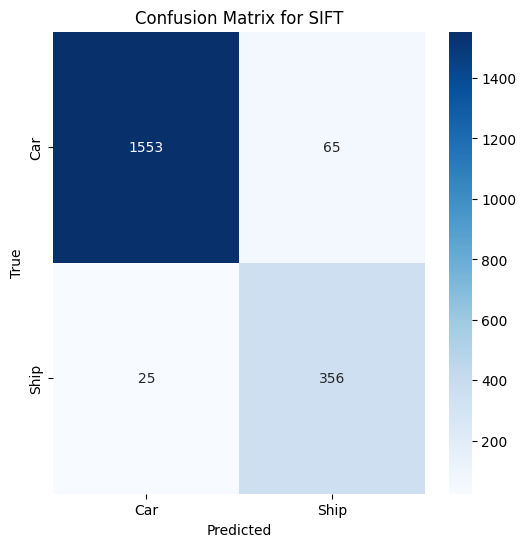

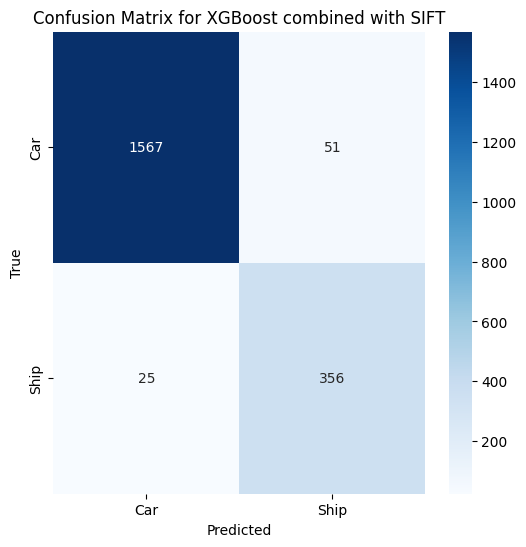

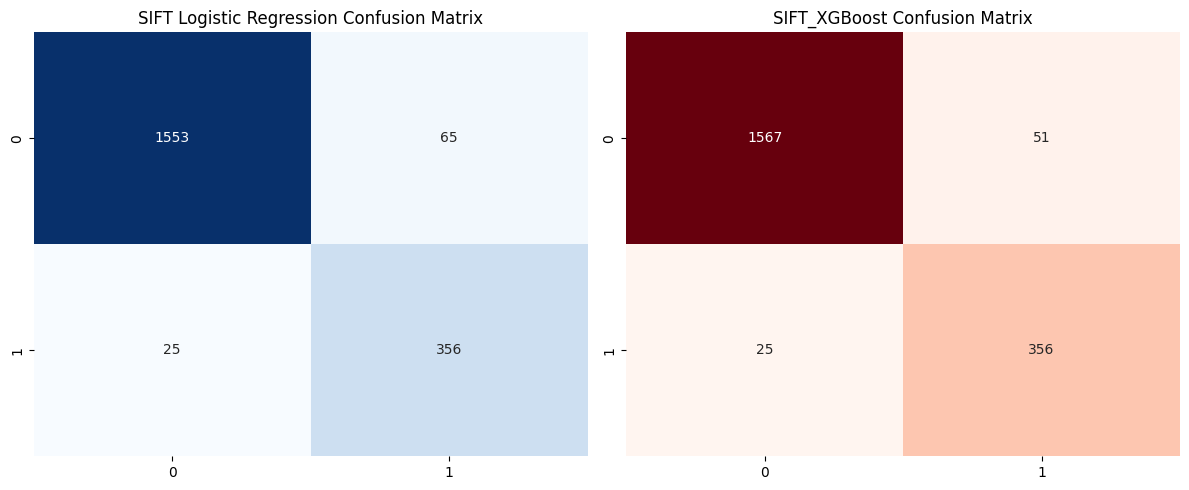

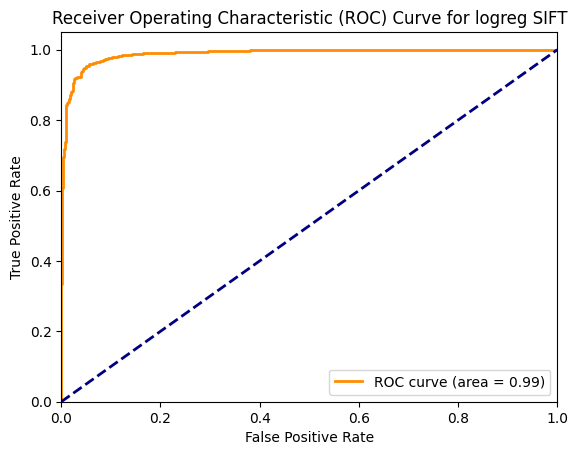

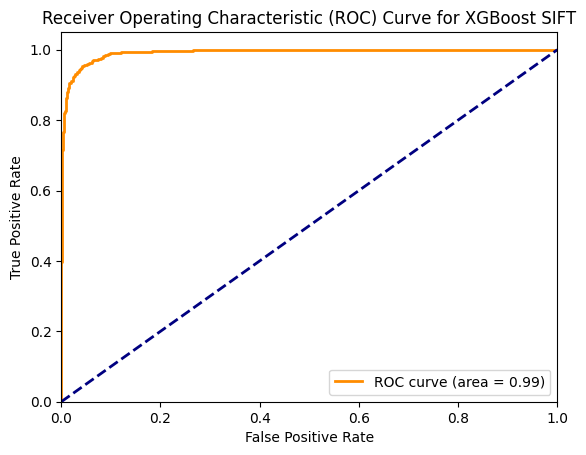

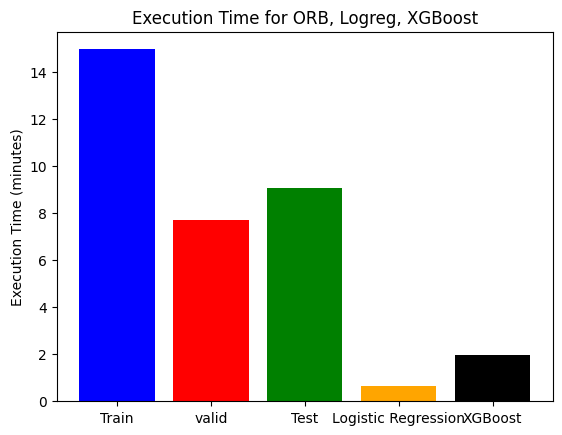

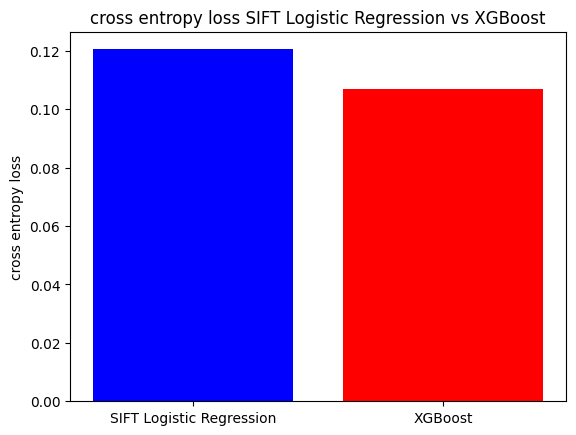

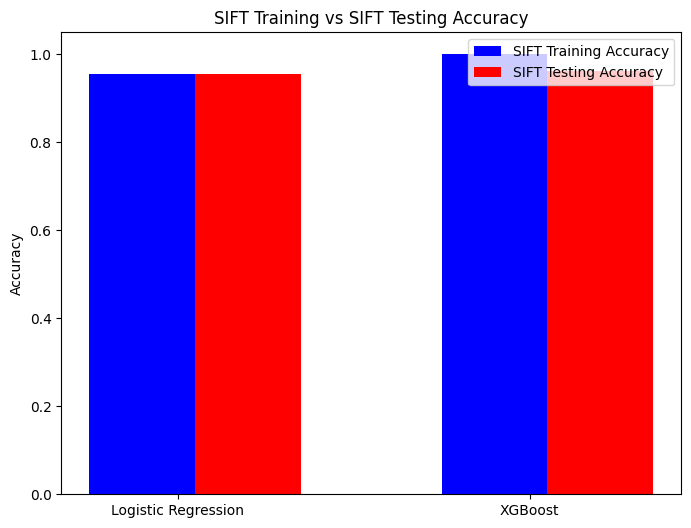

In [15]:
def main():

    # Load training and test data
    traineded_images, filenames = train_image(train_image_path)
    valided_images, filenamesss = valid_image(valid_image_path)
    tested_images, filenamess = test_image(test_image_path)

    # Get valid filenames after SIFT processing
    train_features_SIFT, train_valid_filenames_SIFT, SIFT_execution_train_time_minutes, total_train_keypoints_SIFT \
    = SIFT_train(traineded_images, filenames)
    valid_features_SIFT, valid_valid_filenames_SIFT, SIFT_execution_valid_time_minutes, total_valid_keypoints_SIFT \
    = SIFT_train(valided_images, filenamesss)
    test_features_SIFT, test_valid_filenames_SIFT, SIFT_execution_test_time_minutes, total_test_keypoints_SIFT \
    = SIFT_test(tested_images, filenamess)

    # Load SIFT labels only for valid images (those with keypoints/descriptors)
    train_labels_SIFT = load_train_labels_SIFT(train_txt_path, train_valid_filenames_SIFT)
    valid_labels_SIFT = load_valid_labels_SIFT(valid_txt_path, valid_valid_filenames_SIFT)
    test_labels_SIFT = load_test_labels_SIFT(test_txt_path, test_valid_filenames_SIFT)

    # Proceed with Logistic Regression and XGBoost training SIFT
    y_test, logreg_test_pred_SIFT, train_size_SIFT, xgb_probabilities_SIFT, valid_size_SIFT, test_size_SIFT, \
    class_report_SIFT, train_prediction_SIFT, valid_prediction_SIFT, test_prediction_SIFT, logreg_kf, \
    grid_xgb_kf_regular_SIFT, train_size_XGBoost_SIFT,valid_size_XGBoost_SIFT, train_score_SIFT, valid_score_SIFT, \
    test_score_SIFT, cm_SIFT, train_score_XGBoost_SIFT, valid_score_XGBoost_SIFT, test_score_XGBoost_SIFT, \
    cm_XGBoost_SIFT, cross_entropy_loss_logreg, cross_entropy_loss_XGBoost, logred_train_execution_test_time_minutes,\
    XGBoost_execution_test_time_minutes, test_size_XGBoost_SIFT, valid_score_XGBoost_SIFT, class_report_XGBoost_SIFT \
    = train_test_logreg_SIFT(train_features_SIFT, train_labels_SIFT, valid_features_SIFT, valid_labels_SIFT , \
                             test_features_SIFT, test_labels_SIFT)
    
    prints(total_train_keypoints_SIFT, total_valid_keypoints_SIFT, total_test_keypoints_SIFT, \
    SIFT_execution_valid_time_minutes, SIFT_execution_test_time_minutes, SIFT_execution_train_time_minutes, \
    train_size_SIFT, valid_size_SIFT, test_size_SIFT, class_report_SIFT, train_prediction_SIFT, \
    valid_prediction_SIFT, test_prediction_SIFT, train_score_SIFT, valid_score_SIFT, test_score_SIFT, \
    cm_SIFT, cross_entropy_loss_logreg, logred_train_execution_test_time_minutes, logreg_kf, \
    grid_xgb_kf_regular_SIFT, train_size_XGBoost_SIFT, valid_size_XGBoost_SIFT,test_size_XGBoost_SIFT, \
    train_score_XGBoost_SIFT, valid_score_XGBoost_SIFT, test_score_XGBoost_SIFT, class_report_XGBoost_SIFT, \
    cm_XGBoost_SIFT, cross_entropy_loss_XGBoost, XGBoost_execution_test_time_minutes)

    plots(y_test, logreg_test_pred_SIFT, xgb_probabilities_SIFT, SIFT_execution_valid_time_minutes, \
    SIFT_execution_test_time_minutes, SIFT_execution_train_time_minutes, train_score_SIFT, \
    test_score_SIFT, cm_SIFT, cross_entropy_loss_logreg, logred_train_execution_test_time_minutes, \
    train_score_XGBoost_SIFT, test_score_XGBoost_SIFT, cm_XGBoost_SIFT, cross_entropy_loss_XGBoost, \
    XGBoost_execution_test_time_minutes)

if __name__ == "__main__":
    main()